In [1]:
pip install ultralytics torchmetrics pycocotools scikit-learn matplotlib pandas pillow

   ---------------------------------------- 0.0/983.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/983.4 kB ? eta -:--:--
   ---------- ----------------------------- 262.1/983.4 kB ? eta -:--:--
   ---------- ----------------------------- 262.1/983.4 kB ? eta -:--:--
   ---------- ----------------------------- 262.1/983.4 kB ? eta -:--:--
   -------------------- ----------------- 524.3/983.4 kB 465.6 kB/s eta 0:00:01
   ------------------------------ ------- 786.4/983.4 kB 609.6 kB/s eta 0:00:01
   -------------------------------------- 983.4/983.4 kB 669.1 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


Classi del modello: {0: 'short_sleeved_shirt', 1: 'long_sleeved_shirt', 2: 'short_sleeved_outwear', 3: 'long_sleeved_outwear', 4: 'vest', 5: 'sling', 6: 'shorts', 7: 'trousers', 8: 'skirt', 9: 'short_sleeved_dress', 10: 'long_sleeved_dress', 11: 'vest_dress', 12: 'sling_dress'}
Immagini trovate: 64306
  elaborate 100/64306
  elaborate 200/64306
  elaborate 300/64306
  elaborate 400/64306
  elaborate 500/64306
  elaborate 600/64306
  elaborate 700/64306
  elaborate 800/64306
  elaborate 900/64306
  elaborate 1000/64306
  elaborate 1100/64306
  elaborate 1200/64306
  elaborate 1300/64306
  elaborate 1400/64306
  elaborate 1500/64306
  elaborate 1600/64306
  elaborate 1700/64306
  elaborate 1800/64306
  elaborate 1900/64306
  elaborate 2000/64306
  elaborate 2100/64306
  elaborate 2200/64306
  elaborate 2300/64306
  elaborate 2400/64306
  elaborate 2500/64306
  elaborate 2600/64306
  elaborate 2700/64306
  elaborate 2800/64306
  elaborate 2900/64306
  elaborate 3000/64306
  elaborate 3100

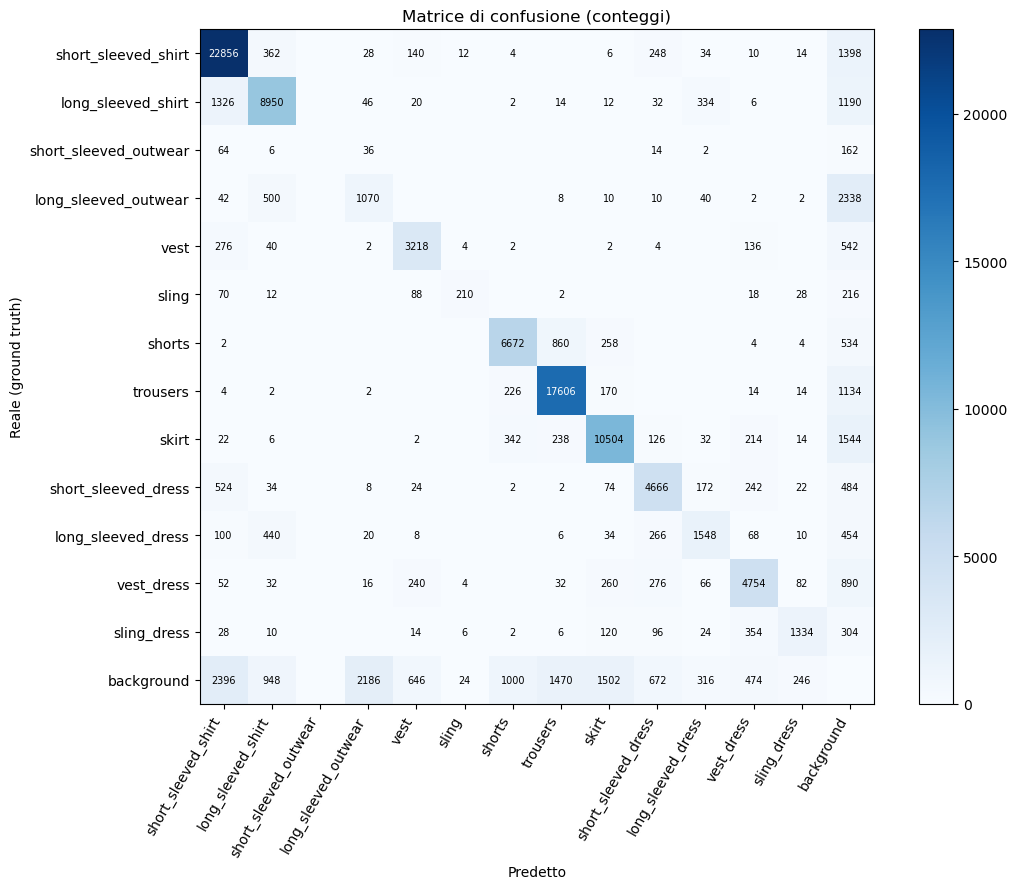

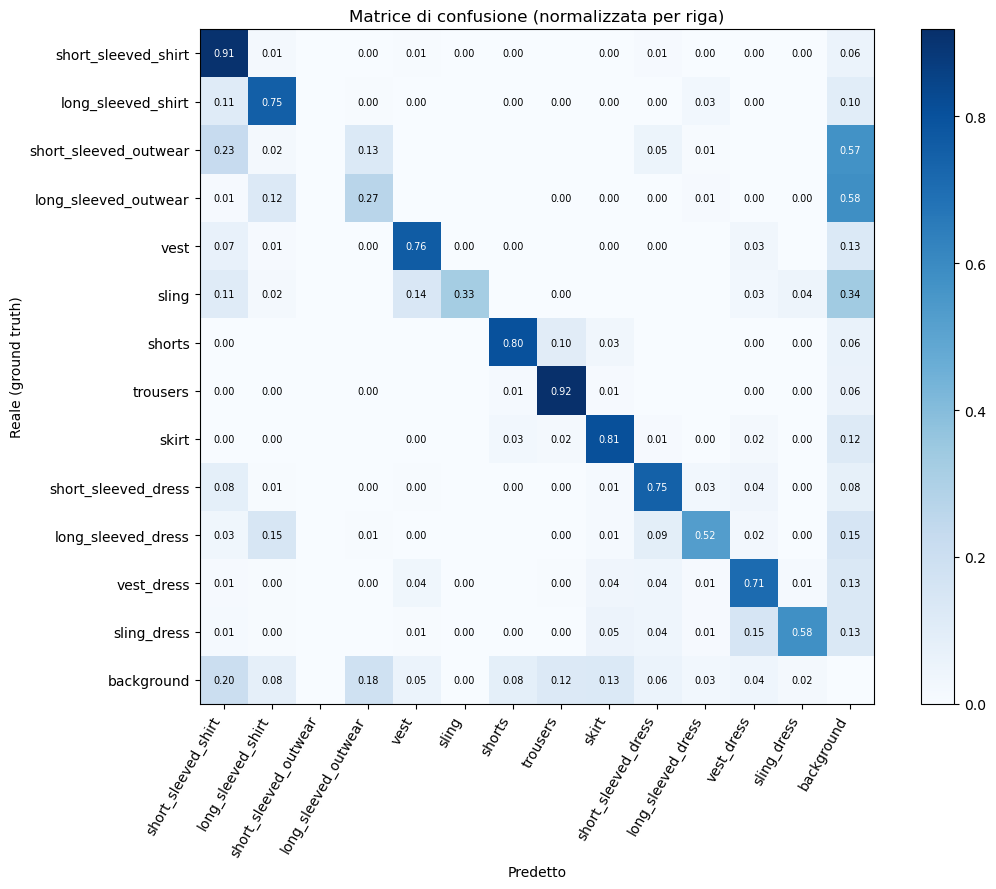


File salvati in: C:\Users\UTENTE\Documents\Università\Computer Vision\Progetto\output_confusion


In [1]:

MODEL_PATH   = "runs/df2/weights/best.pt"   # percorso del modello .pt
IMAGES_DIR   = "validation/image"              # cartella con le immagini (.jpg/.png)
ANNOS_DIR    = "validation/annos"              # cartella con i file json (000002.json, ...)
OUTPUT_DIR   = "output_confusion"              # dove salvare PNG e CSV

CONF_THRES   = 0.25    # soglia di confidenza delle predizioni
NMS_IOU      = 0.7     # IoU usato dalla NMS del modello
MATCH_IOU    = 0.5     # IoU minimo per considerare valido il match GT <-> predizione
IMG_SIZE     = 640     # dimensione di inferenza
DEVICE       = None    # None = automatico, oppure "cpu", "0", "cuda:0"
MAX_IMAGES   = None    # es. 200 per un test veloce, None = tutte
NORMALIZE    = True    # True = disegna anche la matrice normalizzata per riga


import os, glob, json
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Classes
DF2_NAMES = [
    "short sleeve top", "long sleeve top", "short sleeve outwear",
    "long sleeve outwear", "vest", "sling", "shorts", "trousers", "skirt",
    "short sleeve dress", "long sleeve dress", "vest dress", "sling dress",
]


model = YOLO(MODEL_PATH)
model_names = model.names if isinstance(model.names, dict) else dict(enumerate(model.names))
print("Classi del modello:", model_names)

def norm(s):
    return str(s).lower().replace("_", " ").replace("-", " ").strip()

name_to_idx = {norm(v): k for k, v in model_names.items()}
nc = len(model_names)
BG = nc  # indice della classe "background"
labels = [model_names[i] for i in range(nc)] + ["background"]

def gt_class_index(item):
    """Converte la categoria GT di DeepFashion2 nell'indice di classe del modello."""
    n = norm(item.get("category_name", ""))
    if n in name_to_idx:
        return name_to_idx[n]
    cid = int(item["category_id"]) - 1          # fallback: ordine ufficiale DF2
    return cid if 0 <= cid < nc else None

# ------------------------------ Utility --------------------------------------
def iou_matrix(a, b):
    """a: (N,4), b: (M,4) in formato xyxy -> matrice IoU (N,M)."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def load_gt(json_path):
    boxes, classes = [], []
    with open(json_path, "r") as f:
        data = json.load(f)
    for key, item in data.items():
        if not key.startswith("item"):
            continue                              # salta "source", "pair_id"
        c = gt_class_index(item)
        if c is None:
            continue
        boxes.append(item["bounding_box"])        # [x1, y1, x2, y2]
        classes.append(c)
    return np.array(boxes, dtype=float).reshape(-1, 4), np.array(classes, dtype=int)

# ------------------------------ Images -------------------------------------
exts = ("*.jpg", "*.jpeg", "*.png", "*.JPG", "*.JPEG", "*.PNG")
img_paths = sorted(p for e in exts for p in glob.glob(os.path.join(IMAGES_DIR, e)))
if MAX_IMAGES:
    img_paths = img_paths[:MAX_IMAGES]
print(f"Immagini trovate: {len(img_paths)}")

# righe = classe vera (GT), colonne = classe predetta
cm = np.zeros((nc + 1, nc + 1), dtype=int)
skipped = 0

for i, img_path in enumerate(img_paths):
    stem = os.path.splitext(os.path.basename(img_path))[0]
    json_path = os.path.join(ANNOS_DIR, stem + ".json")
    if not os.path.exists(json_path):
        skipped += 1
        continue

    gt_boxes, gt_cls = load_gt(json_path)

    res = model.predict(img_path, conf=CONF_THRES, iou=NMS_IOU, imgsz=IMG_SIZE,
                        device=DEVICE, verbose=False)[0]
    if res.boxes is not None and len(res.boxes):
        pr_boxes = res.boxes.xyxy.cpu().numpy()
        pr_cls = res.boxes.cls.cpu().numpy().astype(int)
        pr_conf = res.boxes.conf.cpu().numpy()
        order = np.argsort(-pr_conf)
        pr_boxes, pr_cls = pr_boxes[order], pr_cls[order]
    else:
        pr_boxes, pr_cls = np.zeros((0, 4)), np.zeros(0, dtype=int)

    # Matching greedy uno-a-uno in base all'IoU
    ious = iou_matrix(gt_boxes, pr_boxes)
    matched_gt, matched_pr = set(), set()
    if ious.size:
        cand = np.argwhere(ious >= MATCH_IOU)
        cand = cand[np.argsort(-ious[cand[:, 0], cand[:, 1]])]
        for g, p in cand:
            if g in matched_gt or p in matched_pr:
                continue
            matched_gt.add(g); matched_pr.add(p)
            cm[gt_cls[g], pr_cls[p]] += 1

    for g in range(len(gt_cls)):                  # GT non trovati -> predetto background
        if g not in matched_gt:
            cm[gt_cls[g], BG] += 1
    for p in range(len(pr_cls)):                  # predizioni senza GT -> falsi positivi
        if p not in matched_pr:
            cm[BG, pr_cls[p]] += 1

    if (i + 1) % 100 == 0:
        print(f"  elaborate {i + 1}/{len(img_paths)}")

print(f"Fatto. Immagini senza json (saltate): {skipped}")


tp = np.diag(cm)[:nc]
precision = tp / np.maximum(cm[:, :nc].sum(axis=0), 1)
recall = tp / np.maximum(cm[:nc, :].sum(axis=1), 1)
print(f"\n{'classe':<24}{'precision':>10}{'recall':>10}")
for k in range(nc):
    print(f"{labels[k]:<24}{precision[k]:>10.3f}{recall[k]:>10.3f}")


np.savetxt(os.path.join(OUTPUT_DIR, "confusion_matrix.csv"), cm, fmt="%d",
           delimiter=",", header=",".join(labels), comments="")


def plot_cm(mat, title, fname, fmt):
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=60, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predetto"); ax.set_ylabel("Reale (ground truth)")
    ax.set_title(title)
    thr = mat.max() / 2 if mat.max() > 0 else 1
    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            v = mat[r, c]
            if v > 0:
                ax.text(c, r, format(v, fmt), ha="center", va="center", fontsize=7,
                        color="white" if v > thr else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.show()

plot_cm(cm, "Matrice di confusione (conteggi)", "confusion_matrix.png", "d")

if NORMALIZE:
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    plot_cm(cm_norm, "Matrice di confusione (normalizzata per riga)",
            "confusion_matrix_normalized.png", ".2f")

print(f"\nFile salvati in: {os.path.abspath(OUTPUT_DIR)}")

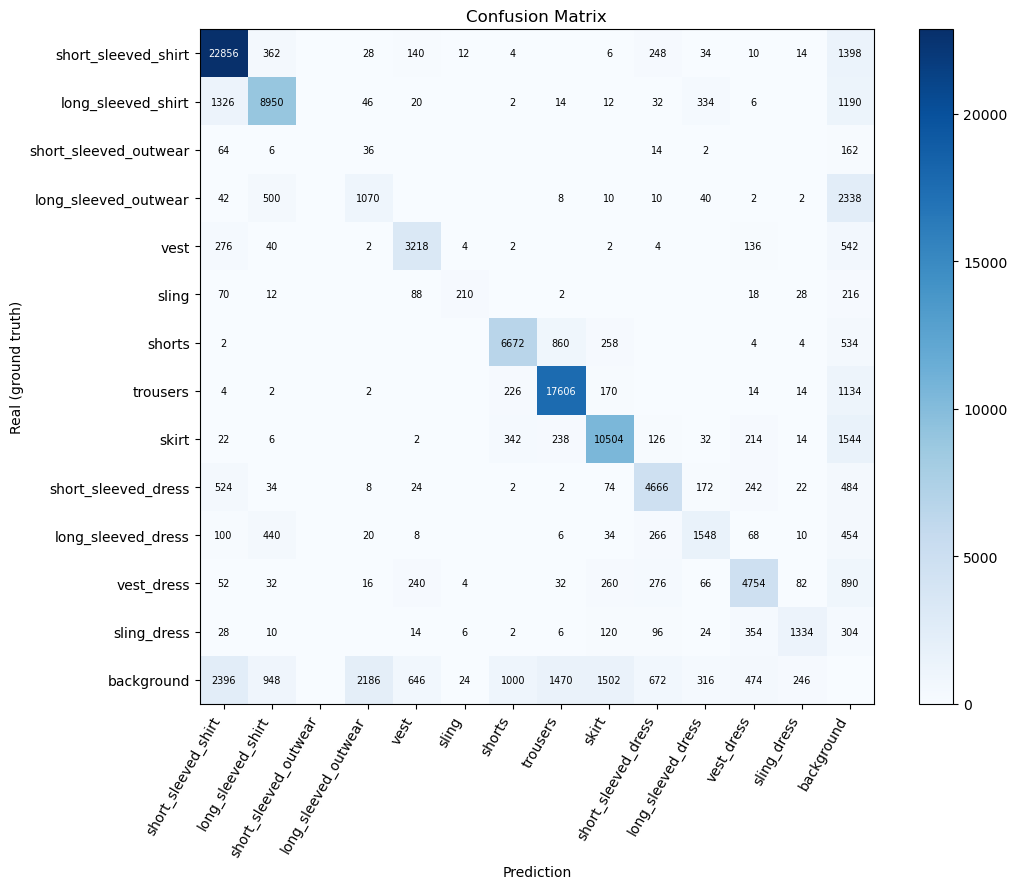

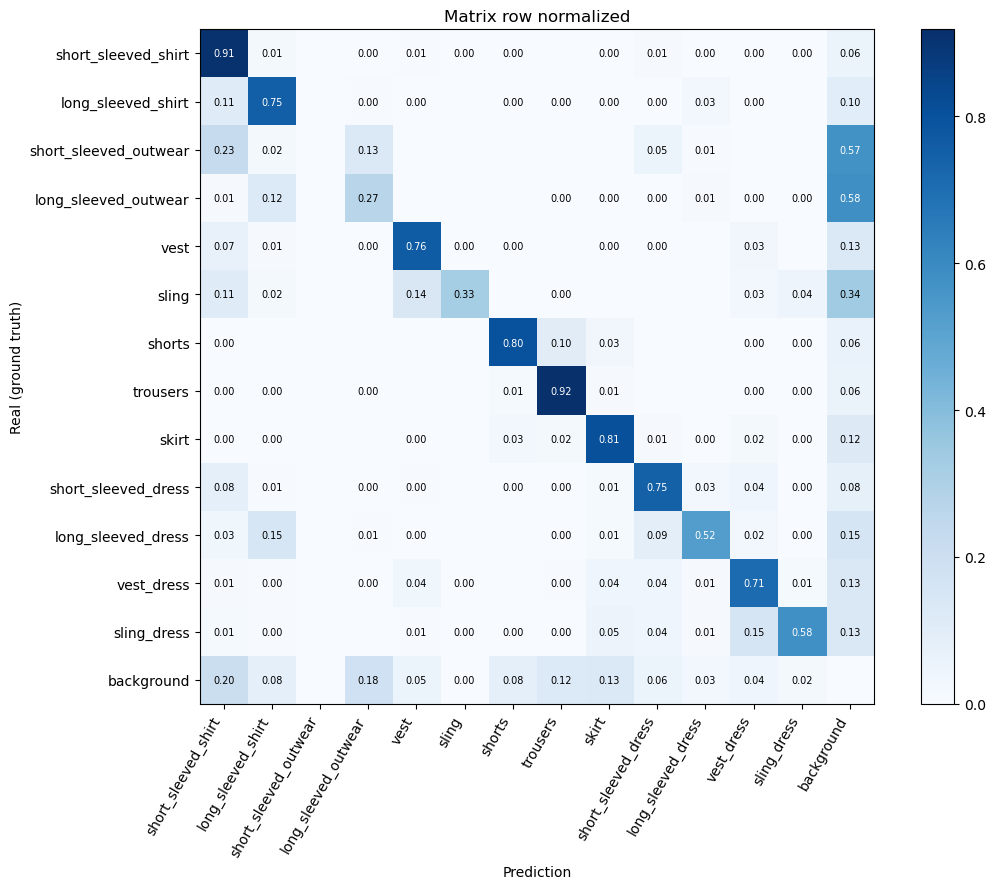


File salvati in: C:\Users\UTENTE\Documents\Università\Computer Vision\Progetto\output_confusion


In [7]:
def plot_cm(mat, title, fname, fmt):
    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=60, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Prediction"); ax.set_ylabel("Real (ground truth)")
    ax.set_title(title)
    thr = mat.max() / 2 if mat.max() > 0 else 1
    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            v = mat[r, c]
            if v > 0:
                ax.text(c, r, format(v, fmt), ha="center", va="center", fontsize=7,
                        color="white" if v > thr else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, fname), dpi=150)
    plt.show()

plot_cm(cm, "Confusion Matrix", "confusion_matrix.png", "d")

if NORMALIZE:
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    plot_cm(cm_norm, "Matrix row normalized",
            "confusion_matrix_normalized.png", ".2f")

print(f"\nFile salvati in: {os.path.abspath(OUTPUT_DIR)}")

In [11]:

import os
import csv
import numpy as np

# Classi reali del dataset (escluso background)
tp = np.diag(cm)[:nc]
fp = cm[:, :nc].sum(axis=0) - tp
fn = cm[:nc, :].sum(axis=1) - tp
support = cm[:nc, :].sum(axis=1)

# Metriche per classe
precision = tp / np.maximum(tp + fp, 1)
recall = tp / np.maximum(tp + fn, 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

# Medie macro
macro_p = precision.mean()
macro_r = recall.mean()
macro_f1 = f1.mean()

# Medie pesate per il numero di istanze reali
if support.sum() > 0:
    weighted_p = np.average(precision, weights=support)
    weighted_r = np.average(recall, weights=support)
    weighted_f1 = np.average(f1, weights=support)
else:
    weighted_p = weighted_r = weighted_f1 = 0.0

# Medie micro
micro_tp = tp.sum()
micro_fp = fp.sum()
micro_fn = fn.sum()

micro_p = micro_tp / max(micro_tp + micro_fp, 1)
micro_r = micro_tp / max(micro_tp + micro_fn, 1)
micro_f1 = 2 * micro_p * micro_r / max(micro_p + micro_r, 1e-12)

# Stampa del report
print("\nREPORT FINALE - YOLO26s-seg / DeepFashion2")
print("-" * 78)
print(f"{'Classe':<27}{'Precision':>12}{'Recall':>12}"
      f"{'F1-score':>12}{'Support':>12}")
print("-" * 78)

for k in range(nc):
    print(f"{labels[k]:<27}{precision[k]:>12.4f}"
          f"{recall[k]:>12.4f}{f1[k]:>12.4f}{support[k]:>12d}")

print("-" * 78)
for name, p, r, score in [
    ("Macro average", macro_p, macro_r, macro_f1),
    ("Weighted average", weighted_p, weighted_r, weighted_f1),
    ("Micro average", micro_p, micro_r, micro_f1),
]:
    print(f"{name:<27}{p:>12.4f}{r:>12.4f}"
          f"{score:>12.4f}{support.sum():>12d}")

print("-" * 78)

# Salvataggio CSV
os.makedirs(OUTPUT_DIR, exist_ok=True)
csv_path = os.path.join(OUTPUT_DIR, "classification_report.csv")

with open(csv_path, "w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(["Classe", "Precision", "Recall", "F1-score", "Support"])

    for k in range(nc):
        writer.writerow([
            labels[k],
            round(float(precision[k]), 6),
            round(float(recall[k]), 6),
            round(float(f1[k]), 6),
            int(support[k])
        ])

    writer.writerow(["Macro average", macro_p, macro_r, macro_f1, int(support.sum())])
    writer.writerow(["Weighted average", weighted_p, weighted_r,
                     weighted_f1, int(support.sum())])
    writer.writerow(["Micro average", micro_p, micro_r,
                     micro_f1, int(support.sum())])

print(f"\nReport salvato in: {os.path.abspath(csv_path)}")



REPORT FINALE - YOLO26s-seg / DeepFashion2
------------------------------------------------------------------------------
Classe                        Precision      Recall    F1-score     Support
------------------------------------------------------------------------------
short_sleeved_shirt              0.8233      0.9102      0.8645       25112
long_sleeved_shirt               0.7891      0.7501      0.7691       11932
short_sleeved_outwear            0.0000      0.0000      0.0000         284
long_sleeved_outwear             0.3134      0.2660      0.2878        4022
vest                             0.7314      0.7615      0.7461        4226
sling                            0.8077      0.3261      0.4646         644
shorts                           0.8085      0.8006      0.8045        8334
trousers                         0.8697      0.9183      0.8933       19172
skirt                            0.8110      0.8053      0.8081       13044
short_sleeved_dress              0.727